# Experiment 001 → 002: Liquid-Staking Carry Walkthrough

This notebook reconstructs the public figures and locked summary tables from local derived outputs. It does not download data, fit parameters, or change an experiment rule. Experiment 002 is a post-Experiment-001 in-sample redesign, not blind OOS evidence.

In [1]:
from __future__ import annotations

import json
import os
import sys
from pathlib import Path

import polars as pl
from IPython.display import SVG, display

cwd = Path.cwd().resolve()
repo_root = cwd.parent if cwd.name == "notebooks" else cwd
sys.path.insert(0, str(repo_root / "src"))
default_data_root = repo_root.parents[1] / "data"
data_root = Path(os.environ.get("QUANT_RESEARCH_DATA_ROOT", default_data_root)).resolve()
asset_dir = repo_root / "docs" / "assets"
print({"repository": repo_root.name, "data_root": "configured locally and excluded from Git"})

{'repository': 'liquid_staking_basis', 'data_root': 'configured locally and excluded from Git'}


## Deterministic figure generation

The same reusable function produces the SVG assets embedded in the GitHub README.

In [2]:
from liquid_staking_basis.visualization import generate_figures

figure_hashes = generate_figures(data_root, asset_dir)
figure_hashes

{'normalized_nav': 'bf27324d0f5ecd349afd53d590ef9585e361a394f95f719be1c68e6d720db294',
 'margin_buffer_stress': '62b07e6d94464d71eceaa27948aa815ae9bfd7a71367ca0b4265c42130e2cec4',
 'p2_drawdown': 'a28deba689ffcb307e1f09eb45d3501df27ed5d8959770a0f80c56654321ca94'}

## Locked experiment outcomes

In [3]:
derived = data_root / "derived" / "liquid_staking_basis"
summaries = {
    experiment: json.loads((derived / experiment / "summary.json").read_text())
    for experiment in ("experiment_001", "experiment_002")
}
rows = []
for experiment, allocation in (("experiment_001", "40 / 60"), ("experiment_002", "25 / 75")):
    summary = summaries[experiment]
    metric = summary["paths"]["primary"]["metrics"]
    rows.append(
        {
            "experiment": experiment.replace("experiment_", ""),
            "allocation": allocation,
            "net_return": metric["total_return"],
            "cagr": metric["cagr"],
            "sharpe": metric["sharpe"],
            "max_drawdown": metric["max_drawdown"],
            "decision": summary["final_label"],
        }
    )
pl.DataFrame(rows)

experiment,allocation,net_return,cagr,sharpe,max_drawdown,decision
str,str,f64,f64,f64,f64,str
"""001""","""40 / 60""",0.424557,0.064108,4.684029,-0.019733,"""economically_rejected"""
"""002""","""25 / 75""",0.254108,0.040561,4.113275,-0.01741,"""economically_supported_isolate…"


## Why Experiment 001 was rejected

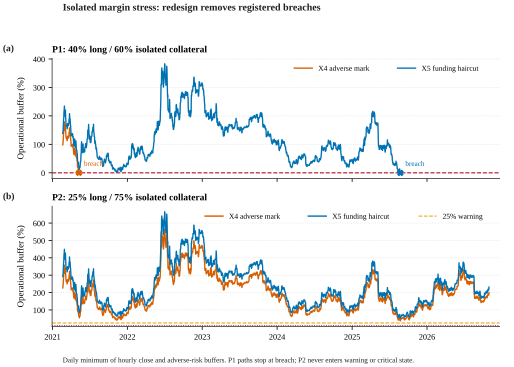

In [4]:
display(SVG(filename=str(asset_dir / "margin_buffer_stress.svg")))

The combined P1 strategy remains profitable, but the isolated futures wallet breaches under X4 and X5. P2 lowers deployed notional and pre-positions collateral instead of assuming an emergency transfer.

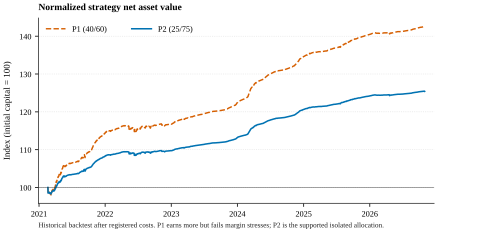

In [5]:
display(SVG(filename=str(asset_dir / "normalized_nav.svg")))

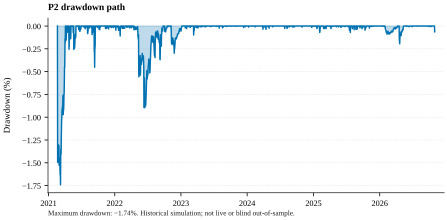

In [6]:
display(SVG(filename=str(asset_dir / "p2_drawdown.svg")))

## Experiment 002 gate audit

In [7]:
p2 = summaries["experiment_002"]
gate_rows = [
    {"gate": name, "passed": passed} for name, passed in p2["economic_gates"]["checks"].items()
]
pl.DataFrame(gate_rows)

gate,passed
str,bool
"""at_least_four_positive_calenda…",true
"""cagr_at_least_3pct""",true
"""calendar_profit_concentration_…",true
"""correctness_gates""",true
"""cost_below_40pct_of_positive_c…",true
…,…
"""minimum_rolling_365d_above_min…",true
"""no_liquidation_primary_and_x1_…",true
"""pre_and_post_shapella_positive""",true


In [8]:
correlation = p2["diversification_analysis"]["correlations"]
portfolio = p2["diversification_analysis"]["portfolio_metrics"]
s4 = p2["diversification_analysis"]["s4_metrics"]
pl.DataFrame(
    {
        "diagnostic": [
            "daily correlation",
            "weekly correlation",
            "monthly correlation",
            "S4 CAGR",
            "75/25 CAGR",
            "S4 Sharpe",
            "75/25 Sharpe",
        ],
        "value": [
            correlation["daily"],
            correlation["weekly"],
            correlation["monthly"],
            s4["cagr"],
            portfolio["cagr"],
            s4["sharpe"],
            portfolio["sharpe"],
        ],
    }
)

diagnostic,value
str,f64
"""daily correlation""",0.048053
"""weekly correlation""",0.529184
"""monthly correlation""",0.644464
"""S4 CAGR""",0.081789
"""75/25 CAGR""",0.072163
"""S4 Sharpe""",4.505748
"""75/25 Sharpe""",5.116513


## Interpretation boundary

P2 is supported as an isolated historical strategy candidate, but it is not accepted as an S4 diversifier under the locked monthly-correlation and portfolio-CAGR gates. The next legitimate evidence is a separately registered forward shadow/paper protocol—not another search over historical capital splits.